# MentalDistress — Step 2 + Step 3 Reproducible Classical Baselines

**Purpose:** complete the canonical reproducible baseline pipeline (Step 2) and run the classical baselines (Step 3) on the locked MentalDistress split.

This notebook intentionally evaluates **validation only**. The locked test split is read only for integrity/hash checks and is **never passed to a model or vectorizer transform for evaluation**.

Models:

1. TF-IDF + Logistic Regression
2. TF-IDF + Linear SVM

Reproducibility policy:

- exact input-file SHA-256 hashes are asserted;
- fixed preprocessing and label order;
- single-thread numerical execution where possible;
- fixed random seed;
- all metrics are generated directly from predictions;
- predictions, scores, confusion matrices, reports, models, vectorizer, and run manifest are saved;
- a second clean refit is performed at the end and required to reproduce **identical validation predictions**.

**Primary development metric:** validation Macro-F1.


In [1]:
# Determinism configuration — run before NumPy/scikit-learn imports.
import os

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
os.environ["BLIS_NUM_THREADS"] = "1"
os.environ["MPLCONFIGDIR"] = "/tmp/matplotlib_mental_distress_repro"
os.makedirs(os.environ["MPLCONFIGDIR"], exist_ok=True)

print(f"PYTHONHASHSEED={os.environ['PYTHONHASHSEED']}")
print("Requested numerical threads = 1")


PYTHONHASHSEED=42
Requested numerical threads = 1


In [2]:
from pathlib import Path
import sys, platform, json, hashlib, shutil, warnings

import numpy as np
import pandas as pd
import scipy
import sklearn
import joblib
import matplotlib.pyplot as plt

from threadpoolctl import threadpool_limits, threadpool_info
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("scikit-learn:", sklearn.__version__)
print("joblib:", joblib.__version__)


Python: 3.13.5
Platform: Linux-6.18.35-x86_64-with-glibc2.41
NumPy: 2.3.5
pandas: 2.2.3
SciPy: 1.17.0
scikit-learn: 1.8.0
joblib: 1.5.3


In [3]:
EXPECTED_ENVIRONMENT = {
    "python": "3.13.5",
    "numpy": "2.3.5",
    "pandas": "2.2.3",
    "scipy": "1.17.0",
    "scikit_learn": "1.8.0",
    "joblib": "1.5.3",
    "matplotlib": "3.10.8",
    "threadpoolctl": "3.6.0",
}

OBSERVED_ENVIRONMENT = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
    "joblib": joblib.__version__,
    "matplotlib": __import__("matplotlib").__version__,
    "threadpoolctl": __import__("threadpoolctl").__version__,
}

assert OBSERVED_ENVIRONMENT == EXPECTED_ENVIRONMENT, (
    "Environment version mismatch. Exact classical-baseline reproduction is certified only "
    "for the pinned environment shown in EXPECTED_ENVIRONMENT."
)

requirements_text = "\n".join([
    "numpy==2.3.5",
    "pandas==2.2.3",
    "scipy==1.17.0",
    "scikit-learn==1.8.0",
    "joblib==1.5.3",
    "matplotlib==3.10.8",
    "threadpoolctl==3.6.0",
]) + "\n"

print("PINNED_ENVIRONMENT: PASS")
print(json.dumps(OBSERVED_ENVIRONMENT, indent=2))


PINNED_ENVIRONMENT: PASS
{
  "python": "3.13.5",
  "numpy": "2.3.5",
  "pandas": "2.2.3",
  "scipy": "1.17.0",
  "scikit_learn": "1.8.0",
  "joblib": "1.5.3",
  "matplotlib": "3.10.8",
  "threadpoolctl": "3.6.0"
}


## 1. Locked input identification

The notebook identifies files by **content hash**, not by filename alone. This allows harmless filename suffixes such as `(1)` while preventing accidental use of a different dataset version.

To rerun elsewhere, set the environment variable `MENTALDISTRESS_DATA_DIR` to the directory containing the four locked CSV files.


In [4]:
EXPECTED_SHA256 = {
    "master": "b189657dcdca2969bc5d158abf0d92b7d0155882ca50ca5ffc248e5b95afece9",
    "train": "1bac0d2f4e0f4d3da940b08a21bd3c6e18b1d958c57cb263c89a900381572d5b",
    "validation": "88835cd714b02efbd230536c7de3f455e807051a23a1786640b0e8b26b430165",
    "test": "e3a61197d1d4a57e61269be260570cc5aa5b504275f0370b1c379f0453517270",
}

EXPECTED_ROWS = {
    "master": 9935,
    "train": 6954,
    "validation": 1490,
    "test": 1491,
}

LABEL_ORDER = ["Suicidal", "Depressed", "Anxious", "Frustrated", "Others"]

EXPECTED_COUNTS = {
    "master": {"Suicidal": 2131, "Depressed": 1458, "Anxious": 1958, "Frustrated": 1846, "Others": 2542},
    "train": {"Suicidal": 1492, "Depressed": 1021, "Anxious": 1370, "Frustrated": 1292, "Others": 1779},
    "validation": {"Suicidal": 319, "Depressed": 219, "Anxious": 294, "Frustrated": 277, "Others": 381},
    "test": {"Suicidal": 320, "Depressed": 218, "Anxious": 294, "Frustrated": 277, "Others": 382},
}

DATA_DIR = Path(os.environ.get("MENTALDISTRESS_DATA_DIR", "/mnt/data")).resolve()
OUTPUT_DIR = Path(os.environ.get("MENTALDISTRESS_OUTPUT_DIR", "/mnt/data/mental_distress_step2_step3_artifacts")).resolve()
# Clean stale artifacts so each execution starts from the same state.
if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_DIR:", DATA_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)


DATA_DIR: /mnt/data
OUTPUT_DIR: /mnt/data/mental_distress_step2_step3_artifacts


In [5]:
def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def resolve_locked_files(data_dir: Path):
    csv_files = sorted(data_dir.rglob("*.csv"))
    if not csv_files:
        raise FileNotFoundError(f"No CSV files found under {data_dir}")

    hash_to_path = {}
    for p in csv_files:
        # Restrict hashing to files that plausibly belong to this project when many CSVs exist.
        if "MentalDistress" not in p.name and "mental" not in p.name.lower():
            continue
        digest = sha256_file(p)
        hash_to_path.setdefault(digest, p)

    resolved = {}
    for role, expected_hash in EXPECTED_SHA256.items():
        if expected_hash not in hash_to_path:
            raise FileNotFoundError(
                f"Could not find locked {role} CSV with SHA-256 {expected_hash} under {data_dir}"
            )
        resolved[role] = hash_to_path[expected_hash]
    return resolved

FILES = resolve_locked_files(DATA_DIR)

file_table = []
for role, path in FILES.items():
    digest = sha256_file(path)
    assert digest == EXPECTED_SHA256[role]
    file_table.append({"role": role, "file": path.name, "sha256": digest, "bytes": path.stat().st_size})

pd.DataFrame(file_table)


,role,file,sha256,bytes
0,master,MentalDistress_LOCKED(1)(1).csv,b189657dcdca2969bc5d158abf0d92b7d0155882ca50ca...,6095935
1,train,MentalDistress_train_LOCKED(2)(1).csv,1bac0d2f4e0f4d3da940b08a21bd3c6e18b1d958c57cb2...,4215478
2,validation,MentalDistress_validation_LOCKED(1)(1).csv,88835cd714b02efbd230536c7de3f455e807051a23a178...,927766
3,test,MentalDistress_test_LOCKED(1)(1).csv,e3a61197d1d4a57e61269be260570cc5aa5b504275f037...,887183


## 2. Integrity verification

These checks are deterministic and must pass before any model fitting.


In [6]:
master = pd.read_csv(FILES["master"])
train = pd.read_csv(FILES["train"])
validation = pd.read_csv(FILES["validation"])
test = pd.read_csv(FILES["test"])

required_master_cols = {"original_row", "text", "label", "text_length", "locked_split"}
required_split_cols = {"original_row", "text", "label", "text_length"}

assert required_master_cols.issubset(master.columns)
for name, df in [("train", train), ("validation", validation), ("test", test)]:
    assert required_split_cols.issubset(df.columns), f"Missing columns in {name}"

for name, df in [("master", master), ("train", train), ("validation", validation), ("test", test)]:
    assert len(df) == EXPECTED_ROWS[name], f"Unexpected row count in {name}"
    assert df["original_row"].is_unique, f"Duplicate original_row in {name}"
    assert not df["text"].isna().any(), f"Null text in {name}"
    assert (df["text"].astype(str).str.strip().str.len() > 0).all(), f"Empty text in {name}"
    assert not df["label"].isna().any(), f"Null label in {name}"
    assert set(df["label"].unique()) == set(LABEL_ORDER), f"Unexpected labels in {name}"
    observed = df["label"].value_counts().to_dict()
    assert observed == EXPECTED_COUNTS[name], f"Unexpected class counts in {name}: {observed}"

train_ids = set(train["original_row"])
val_ids = set(validation["original_row"])
test_ids = set(test["original_row"])
master_ids = set(master["original_row"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)
assert train_ids | val_ids | test_ids == master_ids

# Confirm that master split assignments reproduce the split CSVs.
for split_name, split_df in [("train", train), ("validation", validation), ("test", test)]:
    expected_ids = set(master.loc[master["locked_split"] == split_name, "original_row"])
    assert expected_ids == set(split_df["original_row"]), f"Master/split mismatch for {split_name}"

integrity_summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(df),
        **{label: int((df["label"] == label).sum()) for label in LABEL_ORDER}
    }
    for name, df in [("train", train), ("validation", validation), ("test", test), ("master", master)]
])

print("DATASET_INTEGRITY: PASS")
integrity_summary


DATASET_INTEGRITY: PASS


,split,rows,Suicidal,Depressed,Anxious,Frustrated,Others
0,train,6954,1492,1021,1370,1292,1779
1,validation,1490,319,219,294,277,381
2,test,1491,320,218,294,277,382
3,master,9935,2131,1458,1958,1846,2542


In [7]:
integrity_report = {
    "status": "PASS",
    "input_hashes": EXPECTED_SHA256,
    "rows": EXPECTED_ROWS,
    "label_order": LABEL_ORDER,
    "class_counts": EXPECTED_COUNTS,
    "split_disjoint_by_original_row": True,
    "all_master_rows_accounted_for": True,
    "test_policy": "Integrity/hash checks only; no model fitting, transform, prediction, or metric computation on test in this notebook.",
}

with (OUTPUT_DIR / "dataset_integrity_report.json").open("w", encoding="utf-8") as f:
    json.dump(integrity_report, f, indent=2)

print("Saved:", OUTPUT_DIR / "dataset_integrity_report.json")


Saved: /mnt/data/mental_distress_step2_step3_artifacts/dataset_integrity_report.json


## 3. Fixed classical baseline configuration

There is **no hidden hyperparameter search** in this notebook. The following configuration is fixed and recorded.

The locked corpus is moderately imbalanced, so both linear classifiers use `class_weight='balanced'`. The TF-IDF representation is fit on **training text only**.


**Deterministic-output note:** wall-clock timing is intentionally excluded here because elapsed time varies with system load. Runtime/throughput will be benchmarked later under a dedicated controlled protocol.

In [8]:
TFIDF_CONFIG = {
    "lowercase": True,
    "strip_accents": "unicode",
    "analyzer": "word",
    "token_pattern": r"(?u)\b\w\w+\b",
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 0.98,
    "max_features": 100000,
    "sublinear_tf": True,
    "norm": "l2",
    "dtype": np.float64,
}

LR_CONFIG = {
    "C": 4.0,
    "solver": "lbfgs",
    "max_iter": 3000,
    "random_state": SEED,
    "class_weight": "balanced",
    "tol": 1e-4,
}

SVM_CONFIG = {
    "C": 1.0,
    "random_state": SEED,
    "max_iter": 10000,
    "dual": "auto",
    "class_weight": "balanced",
    "tol": 1e-4,
}

print("TF-IDF:", {k: str(v) if k == "dtype" else v for k, v in TFIDF_CONFIG.items()})
print("Logistic Regression:", LR_CONFIG)
print("Linear SVM:", SVM_CONFIG)


TF-IDF: {'lowercase': True, 'strip_accents': 'unicode', 'analyzer': 'word', 'token_pattern': '(?u)\\b\\w\\w+\\b', 'ngram_range': (1, 2), 'min_df': 2, 'max_df': 0.98, 'max_features': 100000, 'sublinear_tf': True, 'norm': 'l2', 'dtype': "<class 'numpy.float64'>"}
Logistic Regression: {'C': 4.0, 'solver': 'lbfgs', 'max_iter': 3000, 'random_state': 42, 'class_weight': 'balanced', 'tol': 0.0001}
Linear SVM: {'C': 1.0, 'random_state': 42, 'max_iter': 10000, 'dual': 'auto', 'class_weight': 'balanced', 'tol': 0.0001}


## 4. Fit TF-IDF on training text only


In [9]:
vectorizer = TfidfVectorizer(**TFIDF_CONFIG)

with threadpool_limits(limits=1):
    X_train = vectorizer.fit_transform(train["text"].astype(str))
    X_val = vectorizer.transform(validation["text"].astype(str))

assert X_train.shape[0] == len(train)
assert X_val.shape[0] == len(validation)

print("Train TF-IDF shape:", X_train.shape)
print("Validation TF-IDF shape:", X_val.shape)
print("Vocabulary size:", len(vectorizer.vocabulary_))


Train TF-IDF shape: (6954, 74701)
Validation TF-IDF shape: (1490, 74701)
Vocabulary size: 74701


In [10]:
joblib.dump(vectorizer, OUTPUT_DIR / "tfidf_vectorizer.joblib", compress=3)
print("Saved:", OUTPUT_DIR / "tfidf_vectorizer.joblib")


Saved: /mnt/data/mental_distress_step2_step3_artifacts/tfidf_vectorizer.joblib


## 5. Deterministic evaluation helpers


In [11]:
def evaluate_predictions(y_true, y_pred):
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision": float(precision_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, y_pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
        "mcc": float(matthews_corrcoef(y_true, y_pred)),
    }


def save_model_outputs(model_name, model, y_pred, score_matrix, score_columns):
    metrics = evaluate_predictions(validation["label"], y_pred)
    report = classification_report(
        validation["label"], y_pred, labels=LABEL_ORDER, output_dict=True, zero_division=0
    )
    cm = confusion_matrix(validation["label"], y_pred, labels=LABEL_ORDER)

    pred_df = pd.DataFrame({
        "original_row": validation["original_row"].to_numpy(),
        "true_label": validation["label"].to_numpy(),
        "predicted_label": y_pred,
    })
    for idx, col in enumerate(score_columns):
        pred_df[col] = score_matrix[:, idx]

    pred_df.to_csv(OUTPUT_DIR / f"{model_name}_validation_predictions.csv", index=False)
    pd.DataFrame(cm, index=LABEL_ORDER, columns=LABEL_ORDER).to_csv(
        OUTPUT_DIR / f"{model_name}_validation_confusion_matrix.csv"
    )
    pd.DataFrame(report).T.to_csv(OUTPUT_DIR / f"{model_name}_validation_classification_report.csv")

    payload = {
        "model": model_name,
        "split": "validation",
        "seed": SEED,
        "metrics": metrics,
        "confusion_matrix_label_order": LABEL_ORDER,
        "confusion_matrix": cm.tolist(),
    }
    with (OUTPUT_DIR / f"{model_name}_validation_metrics.json").open("w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2)

    joblib.dump(model, OUTPUT_DIR / f"{model_name}.joblib", compress=3)
    return metrics, report, cm, pred_df


## 6. Baseline 1 — TF-IDF + Logistic Regression


In [12]:
lr_model = LogisticRegression(**LR_CONFIG)

with threadpool_limits(limits=1):
    lr_model.fit(X_train, train["label"])
    lr_pred = lr_model.predict(X_val)
    lr_proba = lr_model.predict_proba(X_val)

# scikit-learn stores class columns alphabetically; explicitly label saved probability columns.
lr_score_columns = [f"prob_{cls}" for cls in lr_model.classes_]
lr_metrics, lr_report, lr_cm, lr_pred_df = save_model_outputs(
    "tfidf_logistic_regression", lr_model, lr_pred, lr_proba, lr_score_columns
)

print(json.dumps(lr_metrics, indent=2))


{
  "accuracy": 0.8228187919463087,
  "macro_precision": 0.8206121850686522,
  "macro_recall": 0.8125003649827193,
  "macro_f1": 0.8153138724276247,
  "weighted_f1": 0.8213974589526372,
  "mcc": 0.7766301182757981
}


In [13]:
lr_report_df = pd.DataFrame(lr_report).T
lr_report_df.loc[LABEL_ORDER + ["accuracy", "macro avg", "weighted avg"]]


,precision,recall,f1-score,support
Suicidal,0.790698,0.852665,0.820513,319.000000
Depressed,0.741935,0.630137,0.681481,219.000000
Anxious,0.905085,0.908163,0.906621,294.000000
Frustrated,0.869888,0.844765,0.857143,277.000000
Others,0.795455,0.826772,0.810811,381.000000
accuracy,0.822819,0.822819,0.822819,0.822819
macro avg,0.820612,0.812500,0.815314,1490.000000
weighted avg,0.822039,0.822819,0.821397,1490.000000


In [14]:
pd.DataFrame(lr_cm, index=LABEL_ORDER, columns=LABEL_ORDER)


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,272,21,7,6,13
Depressed,44,138,6,5,26
Anxious,6,8,267,0,13
Frustrated,5,5,4,234,29
Others,17,14,11,24,315


## 7. Baseline 2 — TF-IDF + Linear SVM


In [15]:
svm_model = LinearSVC(**SVM_CONFIG)

with threadpool_limits(limits=1):
    svm_model.fit(X_train, train["label"])
    svm_pred = svm_model.predict(X_val)
    svm_scores = svm_model.decision_function(X_val)

svm_score_columns = [f"decision_{cls}" for cls in svm_model.classes_]
svm_metrics, svm_report, svm_cm, svm_pred_df = save_model_outputs(
    "tfidf_linear_svm", svm_model, svm_pred, svm_scores, svm_score_columns
)

print(json.dumps(svm_metrics, indent=2))


{
  "accuracy": 0.8281879194630872,
  "macro_precision": 0.8272593947312579,
  "macro_recall": 0.8158378037296588,
  "macro_f1": 0.8184787814440743,
  "weighted_f1": 0.8252640393549501,
  "mcc": 0.7837755041762244
}


In [16]:
svm_report_df = pd.DataFrame(svm_report).T
svm_report_df.loc[LABEL_ORDER + ["accuracy", "macro avg", "weighted avg"]]


,precision,recall,f1-score,support
Suicidal,0.789326,0.880878,0.832593,319.000000
Depressed,0.778443,0.593607,0.673575,219.000000
Anxious,0.900990,0.928571,0.914573,294.000000
Frustrated,0.864469,0.851986,0.858182,277.000000
Others,0.803069,0.824147,0.813472,381.000000
accuracy,0.828188,0.828188,0.828188,0.828188
macro avg,0.827259,0.815838,0.818479,1490.000000
weighted avg,0.827243,0.828188,0.825264,1490.000000


In [17]:
pd.DataFrame(svm_cm, index=LABEL_ORDER, columns=LABEL_ORDER)


,Suicidal,Depressed,Anxious,Frustrated,Others
Suicidal,281,16,7,6,9
Depressed,48,130,7,5,29
Anxious,5,7,273,0,9
Frustrated,4,3,4,236,30
Others,18,11,12,26,314


## 8. Validation summary

These are **development validation results**, not final test results.


In [18]:
summary = pd.DataFrame([
    {"model": "TF-IDF + Logistic Regression", **lr_metrics},
    {"model": "TF-IDF + Linear SVM", **svm_metrics},
]).sort_values("macro_f1", ascending=False).reset_index(drop=True)

summary.to_csv(OUTPUT_DIR / "step3_validation_summary.csv", index=False)
summary


,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc
0,TF-IDF + Linear SVM,0.828188,0.827259,0.815838,0.818479,0.825264,0.783776
1,TF-IDF + Logistic Regression,0.822819,0.820612,0.812500,0.815314,0.821397,0.776630


## 9. Inline confusion matrices

The values plotted here are generated directly from the saved validation predictions.


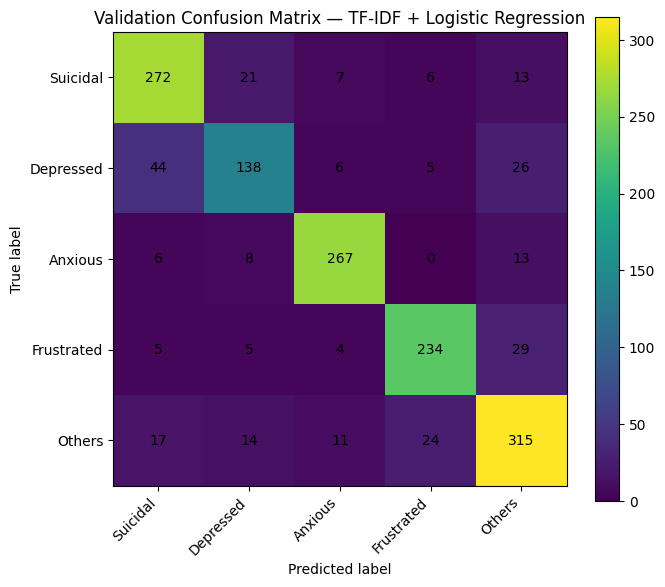

In [19]:
def plot_confusion(cm, title):
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm)
    ax.set_xticks(range(len(LABEL_ORDER)), labels=LABEL_ORDER, rotation=45, ha="right")
    ax.set_yticks(range(len(LABEL_ORDER)), labels=LABEL_ORDER)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, str(cm[i, j]), ha="center", va="center")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    return fig

fig = plot_confusion(lr_cm, "Validation Confusion Matrix — TF-IDF + Logistic Regression")
fig.savefig(OUTPUT_DIR / "tfidf_logistic_regression_validation_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()


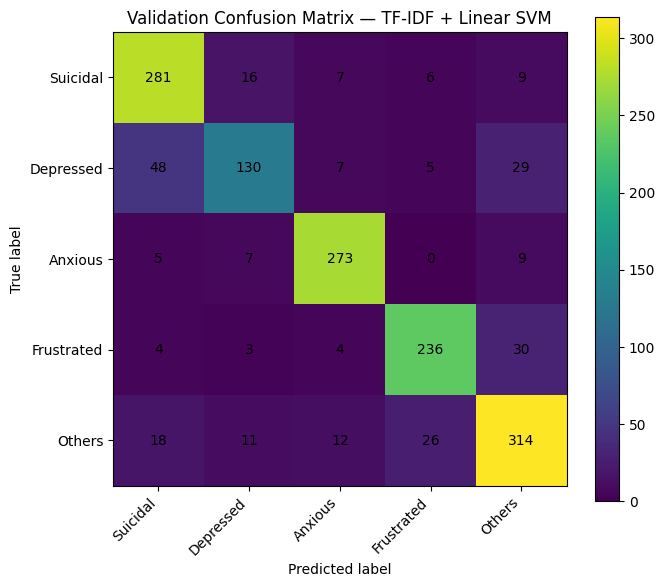

In [20]:
fig = plot_confusion(svm_cm, "Validation Confusion Matrix — TF-IDF + Linear SVM")
fig.savefig(OUTPUT_DIR / "tfidf_linear_svm_validation_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()


## 10. Reproducibility verification — independent second refit

This cell reconstructs the vectorizer and both models from configuration and requires **exactly identical validation predictions** to the first run.

The check is intentionally strict for these CPU classical baselines.


In [21]:
vectorizer_2 = TfidfVectorizer(**TFIDF_CONFIG)

with threadpool_limits(limits=1):
    X_train_2 = vectorizer_2.fit_transform(train["text"].astype(str))
    X_val_2 = vectorizer_2.transform(validation["text"].astype(str))

    lr_model_2 = LogisticRegression(**LR_CONFIG)
    lr_model_2.fit(X_train_2, train["label"])
    lr_pred_2 = lr_model_2.predict(X_val_2)

    svm_model_2 = LinearSVC(**SVM_CONFIG)
    svm_model_2.fit(X_train_2, train["label"])
    svm_pred_2 = svm_model_2.predict(X_val_2)

assert vectorizer.vocabulary_ == vectorizer_2.vocabulary_, "TF-IDF vocabulary changed on second fit"
assert np.array_equal(lr_pred, lr_pred_2), "Logistic Regression predictions changed on second fit"
assert np.array_equal(svm_pred, svm_pred_2), "Linear SVM predictions changed on second fit"
assert evaluate_predictions(validation["label"], lr_pred) == evaluate_predictions(validation["label"], lr_pred_2)
assert evaluate_predictions(validation["label"], svm_pred) == evaluate_predictions(validation["label"], svm_pred_2)

print("SECOND_REFIT_REPRODUCIBILITY: PASS")
print("Logistic Regression predictions identical:", np.array_equal(lr_pred, lr_pred_2))
print("Linear SVM predictions identical:", np.array_equal(svm_pred, svm_pred_2))


SECOND_REFIT_REPRODUCIBILITY: PASS
Logistic Regression predictions identical: True
Linear SVM predictions identical: True


## 11. Saved-artifact reload verification

The persisted vectorizer/models are reloaded and must reproduce the same validation outputs.


In [22]:
loaded_vectorizer = joblib.load(OUTPUT_DIR / "tfidf_vectorizer.joblib")
loaded_lr = joblib.load(OUTPUT_DIR / "tfidf_logistic_regression.joblib")
loaded_svm = joblib.load(OUTPUT_DIR / "tfidf_linear_svm.joblib")

with threadpool_limits(limits=1):
    loaded_X_val = loaded_vectorizer.transform(validation["text"].astype(str))
    loaded_lr_pred = loaded_lr.predict(loaded_X_val)
    loaded_svm_pred = loaded_svm.predict(loaded_X_val)

assert np.array_equal(lr_pred, loaded_lr_pred)
assert np.array_equal(svm_pred, loaded_svm_pred)

print("SAVED_ARTIFACT_RELOAD: PASS")


SAVED_ARTIFACT_RELOAD: PASS


## 12. Run manifest and artifact inventory


In [23]:
manifest = {
    "project": "MentalDistress Q2",
    "stage": "Step 2 + Step 3 classical baselines",
    "status": "PASS",
    "seed": SEED,
    "label_order": LABEL_ORDER,
    "input_files": {role: str(path) for role, path in FILES.items()},
    "input_sha256": EXPECTED_SHA256,
    "environment": OBSERVED_ENVIRONMENT,
    "timing_policy": "Wall-clock timings are intentionally excluded from deterministic result artifacts; benchmark timing separately under a controlled protocol.",
    "tfidf_config": {k: str(v) if k == "dtype" else v for k, v in TFIDF_CONFIG.items()},
    "logistic_regression_config": LR_CONFIG,
    "linear_svm_config": SVM_CONFIG,
    "validation_results": {
        "tfidf_logistic_regression": lr_metrics,
        "tfidf_linear_svm": svm_metrics,
    },
    "reproducibility": {
        "second_refit_exact_predictions": True,
        "saved_artifact_reload_exact_predictions": True,
    },
    "test_evaluation": "NOT_PERFORMED",
}

with (OUTPUT_DIR / "run_manifest.json").open("w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2)

(OUTPUT_DIR / "requirements_step2_step3.txt").write_text(requirements_text, encoding="utf-8")
(OUTPUT_DIR / "environment_snapshot.json").write_text(
    json.dumps(OBSERVED_ENVIRONMENT, indent=2) + "\n", encoding="utf-8"
)

artifact_rows = []
for p in sorted(OUTPUT_DIR.iterdir()):
    if p.is_file():
        artifact_rows.append({
            "file": p.name,
            "bytes": p.stat().st_size,
            "sha256": sha256_file(p),
        })
artifact_df = pd.DataFrame(artifact_rows)
artifact_df.to_csv(OUTPUT_DIR / "artifact_inventory.csv", index=False)

print("RUN_MANIFEST: SAVED")
print("TEST_EVALUATION: NOT_PERFORMED")
artifact_df


RUN_MANIFEST: SAVED
TEST_EVALUATION: NOT_PERFORMED


,file,bytes,sha256
0,dataset_integrity_report.json,1378,132eb988f8f8955a8251fce5dba7ace530cbfcf428bf79...
1,environment_snapshot.json,189,003bcec0fed01046647a1f5cc0ad11bd400d195e7f1171...
2,requirements_step2_step3.txt,115,a61a35d92575fab82342dad60140f4f43206240efaad02...
3,run_manifest.json,2656,f21afeb54e0aad52f4d0ff9aef1ffbb079f86db601890a...
4,step3_validation_summary.csv,346,50aa176930765dee9e93831e16334059816fc060661e21...
5,tfidf_linear_svm.joblib,2609583,3512da0ca7d044c8857e0ee3e74950188613df011cd89e...
6,tfidf_linear_svm_validation_classification_rep...,625,43e976741486cc5300fa63b2d23e09ef31503f21f96807...
7,tfidf_linear_svm_validation_confusion_matrix.csv,159,44764e65ec351ba50dd51ae87a34705475516dd8b859a8...
8,tfidf_linear_svm_validation_confusion_matrix.png,88645,0eb6dd043150794e09c3cbe5b735020cdc9350d300ce64...
9,tfidf_linear_svm_validation_metrics.json,767,bd45bb20ca67635ccb6bd56e74f0b9aca500d77895e76a...


## Final status

A successful execution must end with all of the following:

- `DATASET_INTEGRITY: PASS`
- `SECOND_REFIT_REPRODUCIBILITY: PASS`
- `SAVED_ARTIFACT_RELOAD: PASS`
- `TEST_EVALUATION: NOT_PERFORMED`

The notebook's visible validation results and figures are generated from the same saved predictions used for the machine-readable artifacts.


In [24]:
assert integrity_report["status"] == "PASS"
assert np.array_equal(lr_pred, lr_pred_2)
assert np.array_equal(svm_pred, svm_pred_2)
assert np.array_equal(lr_pred, loaded_lr_pred)
assert np.array_equal(svm_pred, loaded_svm_pred)

print("STEP_2_PIPELINE: COMPLETE")
print("STEP_3_CLASSICAL_BASELINES: COMPLETE")
print("REPRODUCIBILITY_CHECK: PASS")
print("TEST_EVALUATION: NOT_PERFORMED")


STEP_2_PIPELINE: COMPLETE
STEP_3_CLASSICAL_BASELINES: COMPLETE
REPRODUCIBILITY_CHECK: PASS
TEST_EVALUATION: NOT_PERFORMED
